In [ ]:
import tensorflow as tf
print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Dataset information
print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing data shape: (10000, 28, 28)
Testing labels shape: (10000,)


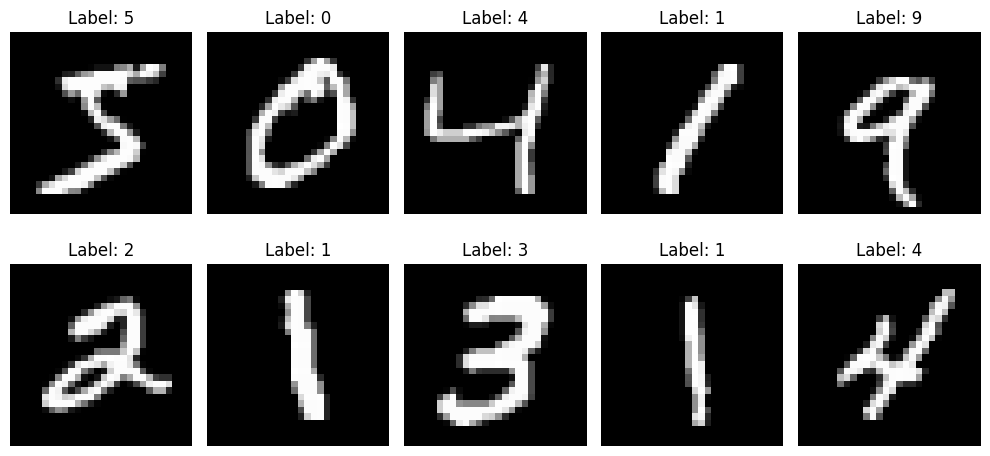

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Normalize pixel values

In [ ]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Testing data range:", X_test.min(), "to", X_test.max())

Training data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0


# Normalize pixel values

In [ ]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("New training shape:", X_train.shape)
print("New testing shape:", X_test.shape)

New training shape: (60000, 28, 28, 1)
New testing shape: (10000, 28, 28, 1)


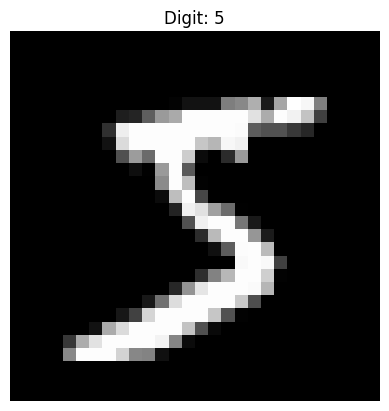

In [ ]:
plt.imshow(X_train[0].reshape(28, 28), cmap='gray')
plt.title(f"Digit: {y_train[0]}")
plt.axis('off')
plt.show()

In [24]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([

    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.5),

    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model compiled successfully!")

CNN Model compiled successfully!


 Train the CNN model

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 50s 57ms/step - accuracy: 0.9157 - loss: 0.2764 - val_accuracy: 0.9842 - val_loss: 0.0510
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 55ms/step - accuracy: 0.9713 - loss: 0.0944 - val_accuracy: 0.9875 - val_loss: 0.0438
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 57ms/step - accuracy: 0.9798 - loss: 0.0685 - val_accuracy: 0.9897 - val_loss: 0.0377
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.9827 - loss: 0.0554 - val_accuracy: 0.9913 - val_loss: 0.0316
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 57ms/step - accuracy: 0.9855 - loss: 0.0462 - val_accuracy: 0.9908 - val_loss: 0.0307
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 55ms/step - accuracy: 0.9880 - loss: 0.0383 - val_accuracy: 0.9923 - val_loss: 0.0300
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 53ms/step - accuracy: 0.9892 - loss: 0.0357 - val_accuracy: 0.9908 - val_loss: 0.0301
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 85s 57ms/step - accuracy: 0.9900 - loss: 0.0309 - 

Accuracy & Loss Graph


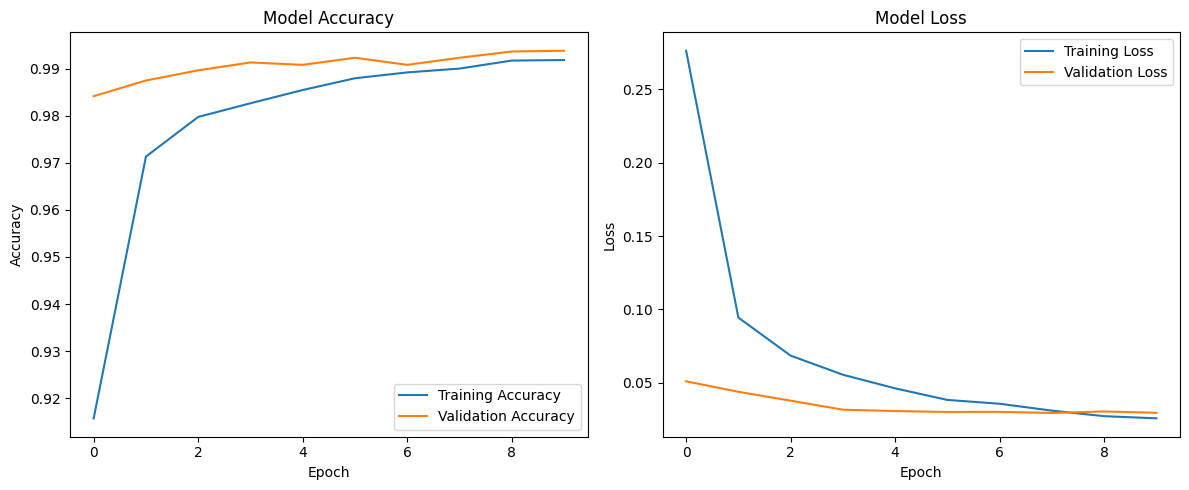

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print("\nTest Results:")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9925 - loss: 0.0230

Test Results:
Test Loss: 0.0230
Test Accuracy: 0.9925
Test Accuracy (%): 99.25%


 Predict test images

In [17]:
y_pred_probs = model.predict(X_test)

y_pred = np.argmax(y_pred_probs, axis=1)

print("Prediction completed successfully!")
print("First 10 Predictions:", y_pred[:10])
print("Actual Labels:", y_test[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Prediction completed successfully!
First 10 Predictions: [7 2 1 0 4 1 4 9 5 9]
Actual Labels: [7 2 1 0 4 1 4 9 5 9]


Classification Report

In [18]:
from sklearn.metrics import classification_report
print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

Classification Report:
              precision    recall  f1-score   support

           0     0.9959    0.9949    0.9954       980
           1     0.9982    0.9938    0.9960      1135
           2     0.9951    0.9913    0.9932      1032
           3     0.9931    0.9931    0.9931      1010
           4     0.9959    0.9929    0.9944       982
           5     0.9811    0.9910    0.9861       892
           6     0.9948    0.9896    0.9922       958
           7     0.9856    0.9971    0.9913      1028
           8     0.9938    0.9918    0.9928       974
           9     0.9901    0.9891    0.9896      1009

    accuracy                         0.9925     10000
   macro avg     0.9924    0.9925    0.9924     10000
weighted avg     0.9925    0.9925    0.9925     10000



Confusion Matrix

<Figure size 900x900 with 0 Axes>

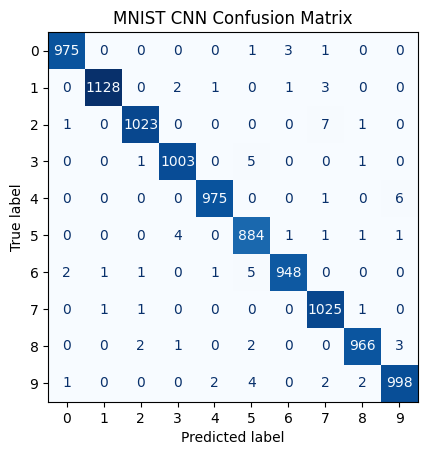

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap='Blues', values_format='d', colorbar=False)
plt.title("MNIST CNN Confusion Matrix")
plt.show()

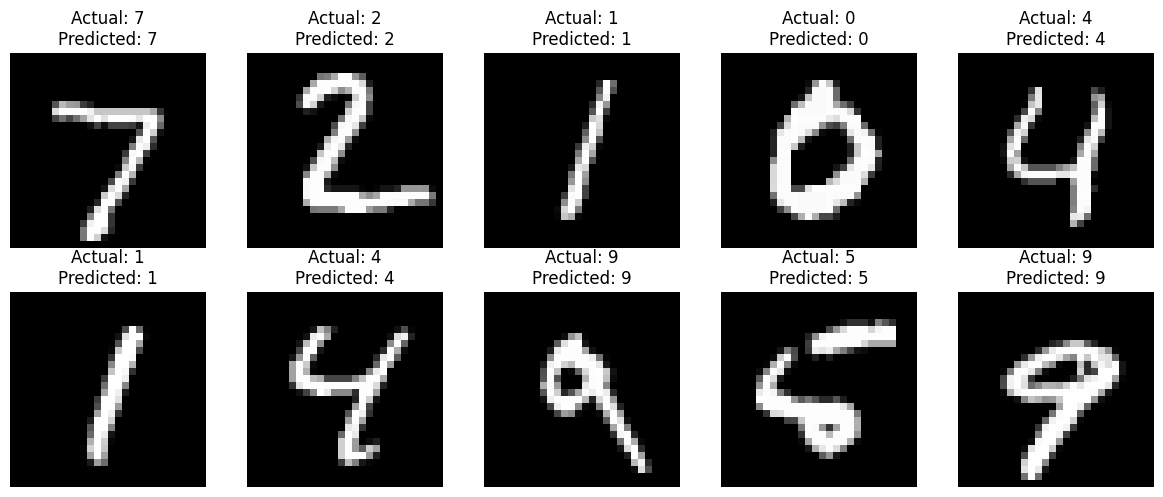

In [20]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

 Save the trained CNN model

In [21]:
model.save("handwritten_digit_cnn.keras")
print("Model saved successfully!")

Model saved successfully!


In [25]:
from google.colab import files
files.download("handwritten_digit_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>